# Industrial Engineering Knowledge Assistant
## Milestone 1 · P&ID image → OCR → structured JSON

Render the supplied P&ID, recognize text locally, retain geometry and confidence, and inspect the result. **No RAG, embeddings, database or LLM.** Streamlit is a later milestone.

Run all cells in order using the project's `.venv` kernel. The default input is `data/p&ids/reference_pid.svg`. SVG text nodes are extracted separately at the end for comparison; they are **not** used as OCR results. RapidOCR uses bundled ONNX OCR models on CPU; no API key or inference service is needed.

Outputs: `reference_pid_ocr.json`, `reference_pid_ocr_annotated.png`, and `reference_pid_ocr_summary.csv` under `outputs/`. A clean `reference_pid.png` is also saved for traceability.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import io
import json
import math
import re
import time
import unicodedata

import cairosvg
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont, ImageOps
from IPython.display import display
from rapidocr_onnxruntime import RapidOCR

# Locate the project from either its root or notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from the project root or notebooks directory.")
INPUT_PATH = ROOT / "data" / "p&ids" / "reference_pid.svg"
OUTPUT_DIR = ROOT / "outputs"
DOCUMENT_ID = "dexpi_reference_pid"
PAGE = 1                         # One-based; select a single page for PDF input.
TARGET_WIDTH = 5000              # Tunable starting point, not a standard or an optimized value.
TILE_SIZE = 1600
TILE_OVERLAP = 320
OCR_ROTATIONS = (0, 90, 270)     # Counterclockwise quarter turns; keep rotated vertical regions.
TILE_EDGE_MARGIN = 12            # Pixels near an internal crop boundary.
REVIEW_THRESHOLD = 0.80          # Flag for review, never discard based on this threshold.
# Inner frame bounds for this drawing, in normalized page coordinates.
# Configure these for drawings with a different border layout.
DRAWING_CONTENT_BOUNDS = {"x_min": 0.01, "y_min": 0.015, "x_max": 0.99, "y_max": 0.985}
# Manually configured layout zones for this reference drawing (normalized coordinates).
REGION_ZONES = {
    "title_block": [{"x_min": 0.70, "y_min": 0.88, "x_max": 0.99, "y_max": 0.985}],
    "equipment_data_table": [
        {"x_min": 0.01, "y_min": 0.79, "x_max": 0.45, "y_max": 0.89},
        {"x_min": 0.01, "y_min": 0.89, "x_max": 0.67, "y_max": 0.985},
    ],
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
assert INPUT_PATH.is_file(), INPUT_PATH
assert TARGET_WIDTH > 0 and 0 <= TILE_OVERLAP < TILE_SIZE
print(f"Input: {INPUT_PATH.relative_to(ROOT)}")
print(f"RapidOCR: {version('rapidocr-onnxruntime')}")

Input: data/p&ids/reference_pid.svg
RapidOCR: 1.4.4


## 1. Render a high-resolution image

SVG uses CairoSVG on a white background. PDF uses PDFium to render the selected page. PNG is composited on white and resized. The rendering width is a configurable quality/runtime tradeoff, not a required dimension. The height is calculated from the source aspect ratio. Upscaling an existing PNG cannot recover missing source detail.

Coordinates refer to the **rendered image**, with `(0, 0)` at its top-left; x increases right and y increases down.

Rendered 5,000 × 3,536 pixels → reference_pid.png


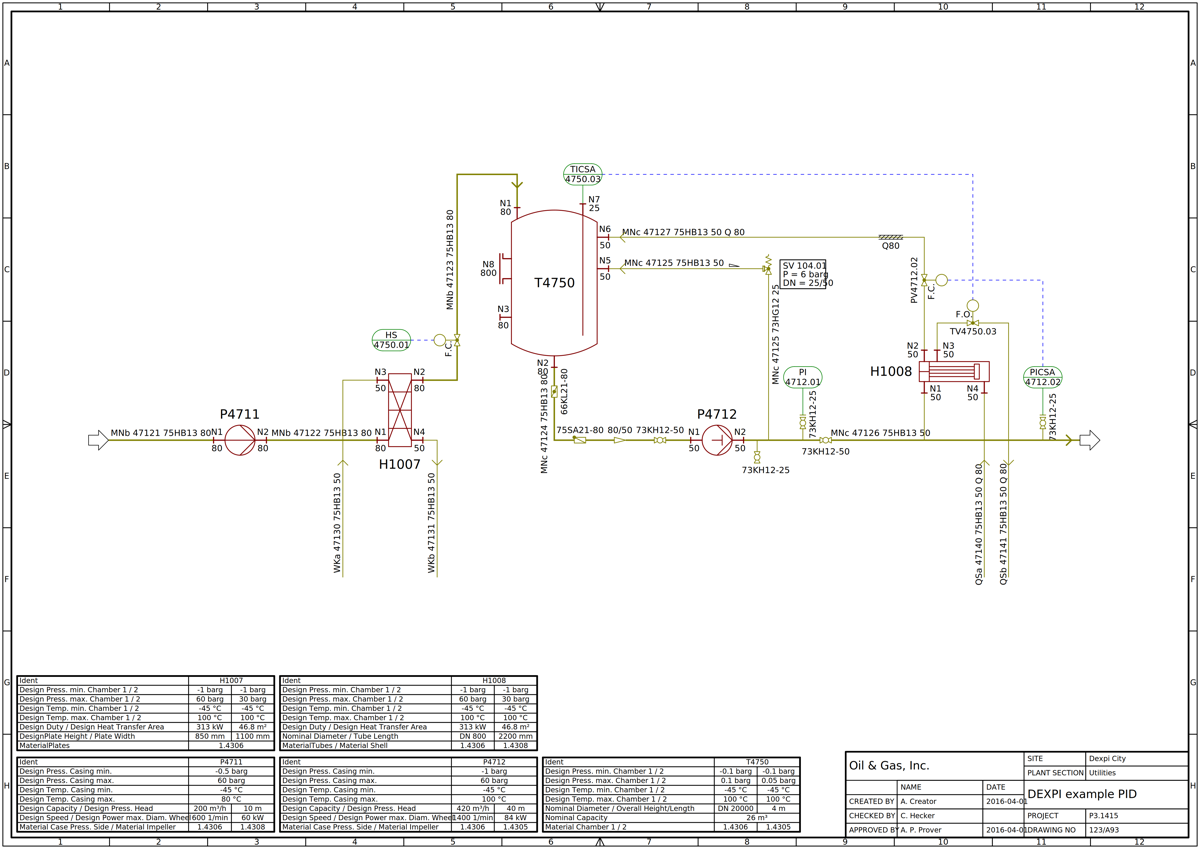

In [2]:
def render_input(path, target_width, page=1):
    suffix = path.suffix.lower()
    if page < 1:
        raise ValueError("PAGE must be one-based.")
    if suffix != ".pdf" and page != 1:
        raise ValueError("SVG and PNG inputs have one page.")
    if suffix == ".svg":
        png = cairosvg.svg2png(url=str(path), output_width=target_width,
                              background_color="white")
        return Image.open(io.BytesIO(png)).convert("RGB")
    if suffix == ".pdf":
        import pypdfium2 as pdfium
        document = pdfium.PdfDocument(str(path))
        try:
            if page > len(document):
                raise ValueError(f"PDF has {len(document)} pages, requested {page}.")
            pdf_page = document[page - 1]
            try:
                bitmap = pdf_page.render(scale=target_width / pdf_page.get_width())
                try:
                    return bitmap.to_pil().convert("RGB").copy()
                finally:
                    bitmap.close()
            finally:
                pdf_page.close()
        finally:
            document.close()
    if suffix == ".png":
        with Image.open(path) as source:
            rgba = ImageOps.exif_transpose(source).convert("RGBA")
            background = Image.new("RGBA", rgba.size, "white")
            background.alpha_composite(rgba)
            rgb = background.convert("RGB")
            height = round(rgb.height * target_width / rgb.width)
            return rgb.resize((target_width, height), Image.Resampling.LANCZOS)
    raise ValueError("Supported inputs: SVG, PDF, PNG")

pid_image = render_input(INPUT_PATH, TARGET_WIDTH, PAGE)
IMAGE_WIDTH, IMAGE_HEIGHT = pid_image.size
RENDER_PATH = OUTPUT_DIR / "reference_pid.png"
pid_image.save(RENDER_PATH)
print(f"Rendered {IMAGE_WIDTH:,} × {IMAGE_HEIGHT:,} pixels → {RENDER_PATH.name}")
display(pid_image.resize((1200, round(1200 * IMAGE_HEIGHT / IMAGE_WIDTH))))

## 2. OCR on overlapping tiles, with rotated passes

Run OCR on each tile at 0°, 90° and 270° counterclockwise. Additional rotations make vertical writing horizontal for the detector. Map every polygon back into the unrotated tile and then into page coordinates. Only tall regions (height at least 1.5 × width in the original image) are accepted from rotated passes; horizontal text remains handled by the original pass. Long text regions are kept intact for `contains` searches.

Flag boxes near **internal tile edges**, where text may have been clipped. True outer page edges are not treated as tile seams. Save every accepted candidate and its pass provenance for audit before deduplication.

All non-empty original-pass readings remain candidates, even at low confidence. Rotated passes add opportunities, not guaranteed correctness. Confidence is recognition confidence, not proof of complete text or correct geometry.

In [3]:
def tile_starts(length, size, overlap):
    if length <= size:
        return [0]
    starts = list(range(0, length - size + 1, size - overlap))
    if starts[-1] != length - size:
        starts.append(length - size)
    return starts


def unrotate_points(points, angle, width, height):
    """Inverse of np.rot90 on continuous image-boundary coordinates."""
    points = np.asarray(points, dtype=float)
    x, y = points[:, 0], points[:, 1]
    if angle == 0:
        return points.copy()
    if angle == 90:
        return np.column_stack((width - y, x))
    if angle == 270:
        return np.column_stack((y, height - x))
    raise ValueError("Only 0, 90 and 270 degree passes are supported.")


def internal_edge_flags(box, tile_bounds, page_width, page_height, margin):
    x0, y0, x1, y1 = box
    left, top, right, bottom = tile_bounds
    return [name for name, touches in (
        ("left", left > 0 and x0 - left <= margin),
        ("top", top > 0 and y0 - top <= margin),
        ("right", right < page_width and right - x1 <= margin),
        ("bottom", bottom < page_height and bottom - y1 <= margin),
    ) if touches]

ocr = RapidOCR(text_score=0.0, det_limit_side_len=TILE_SIZE,
               det_limit_type="max", intra_op_num_threads=4,
               inter_op_num_threads=1)
candidates = []
tiles = [(x, y) for y in tile_starts(IMAGE_HEIGHT, TILE_SIZE, TILE_OVERLAP)
         for x in tile_starts(IMAGE_WIDTH, TILE_SIZE, TILE_OVERLAP)]
started = time.perf_counter()
for tile_number, (left, top) in enumerate(tiles, start=1):
    tile_bounds = [left, top, min(left + TILE_SIZE, IMAGE_WIDTH), min(top + TILE_SIZE, IMAGE_HEIGHT)]
    tile = pid_image.crop(tile_bounds)
    rgb = np.asarray(tile)
    for angle in OCR_ROTATIONS:
        rotated = np.rot90(rgb, k=angle // 90)
        result, _ = ocr(rotated[:, :, ::-1].copy())  # RapidOCR ndarray convention: BGR.
        accepted = 0
        for polygon, text, confidence in result or []:
            if not text.strip():
                continue
            local = unrotate_points(polygon, angle, tile.width, tile.height)
            local[:, 0] = np.clip(local[:, 0], 0, tile.width)
            local[:, 1] = np.clip(local[:, 1], 0, tile.height)
            points = local + [left, top]
            x_min, y_min = np.floor(points.min(axis=0)).astype(int)
            x_max, y_max = np.ceil(points.max(axis=0)).astype(int)
            if x_max <= x_min or y_max <= y_min:
                continue
            if angle and y_max - y_min < 1.5 * (x_max - x_min):
                continue
            box = [int(x_min), int(y_min), int(x_max), int(y_max)]
            edges = internal_edge_flags(box, tile_bounds, IMAGE_WIDTH, IMAGE_HEIGHT, TILE_EDGE_MARGIN)
            candidates.append({
                "candidate_id": f"candidate-{len(candidates) + 1:05d}",
                "text_raw": str(text), "confidence": float(confidence),
                "box": box, "polygon": points.tolist(), "tile": tile_number,
                "rotation_ccw": angle, "tile_bounds": tile_bounds,
                "internal_tile_edges": edges, "near_internal_tile_edge": bool(edges),
            })
            accepted += 1
        print(f"Tile {tile_number:02}/{len(tiles)}, rotation {angle:3}°: {accepted} accepted regions", flush=True)
ocr_elapsed = time.perf_counter() - started
CANDIDATE_PATH = OUTPUT_DIR / "reference_pid_ocr_candidates.json"
CANDIDATE_PATH.write_text(json.dumps({"document_id": DOCUMENT_ID, "page": PAGE,
    "source_sha256": hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest(),
    "image_width": IMAGE_WIDTH, "image_height": IMAGE_HEIGHT,
    "candidates": candidates}, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
print(f"{len(candidates)} candidates in {ocr_elapsed:.1f}s; saved {CANDIDATE_PATH.name}")

Tile 01/12, rotation   0°: 10 accepted regions


Tile 01/12, rotation  90°: 0 accepted regions


Tile 01/12, rotation 270°: 0 accepted regions


Tile 02/12, rotation   0°: 29 accepted regions


Tile 02/12, rotation  90°: 5 accepted regions


...

Tile 11/12, rotation 270°: 1 accepted regions


Tile 12/12, rotation   0°: 32 accepted regions


Tile 12/12, rotation  90°: 3 accepted regions


Tile 12/12, rotation 270°: 2 accepted regions


435 candidates in 35.1s; saved reference_pid_ocr_candidates.json


## 3. Select complete overlapping readings and normalize

Overlapping candidates from different tiles **or rotation passes** can describe the same text. First prefer candidates away from internal tile edges; then prefer readings above the review threshold; then prefer greater text-line extent; finally use confidence to break ties. This gives complete interior readings priority over high-confidence clipped fragments. It is still a heuristic: longer regions are not automatically correct, and low-confidence/non-edge preferences can need manual review.

Suppress a candidate only when at least 70% of its smaller box overlaps a retained region and the regions have compatible orientation and alignment. Repeated labels at different locations remain separate. Save suppressed readings, rotation and edge flags under `overlap_alternatives`; all original candidates are also exported separately. Rotations can rescue vertical labels without splitting long strings.

Normalize Unicode, whitespace, and dash variants without guessing character substitutions. Pixel coordinates and normalized coordinates always refer to the original, unrotated page. Detection IDs may change after adding or changing readings; compare text and location rather than relying on old IDs.

In [4]:
def normalize_text(text):
    text = unicodedata.normalize("NFKC", text)
    text = text.translate(str.maketrans({char: "-" for char in "‐‑‒–—−"}))
    text = re.sub(r"\s+", " ", text).strip()
    return re.sub(r"\s*-\s*", "-", text)


def overlap_fraction(a, b):
    x0, y0 = max(a[0], b[0]), max(a[1], b[1])
    x1, y1 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x1 - x0) * max(0, y1 - y0)
    smaller = min((a[2] - a[0]) * (a[3] - a[1]),
                  (b[2] - b[0]) * (b[3] - b[1]))
    return intersection / smaller if smaller else 0.0

def same_text_region(a, b):
    if (a["tile"], a["rotation_ccw"]) == (b["tile"], b["rotation_ccw"]):
        return False
    if overlap_fraction(a["box"], b["box"]) < 0.70:
        return False
    ax0, ay0, ax1, ay1 = a["box"]
    bx0, by0, bx1, by1 = b["box"]
    aw, ah, bw, bh = ax1 - ax0, ay1 - ay0, bx1 - bx0, by1 - by0
    av, bv = ah > 1.5 * aw, bh > 1.5 * bw
    # Preserve adjacent labels with different orientations rather than
    # allowing a large rotated region to swallow a horizontal label.
    if av != bv:
        return False
    if av or bv:
        return abs((ax0 + ax1 - bx0 - bx1) / 2) <= 0.5 * max(aw, bw)
    return abs((ay0 + ay1 - by0 - by1) / 2) <= 0.5 * max(ah, bh)


def selection_priority(item):
    x0, y0, x1, y1 = item["box"]
    return (not item["near_internal_tile_edge"],
            item["confidence"] >= REVIEW_THRESHOLD,
            max(x1 - x0, y1 - y0), item["confidence"])


def deduplicate_candidates(items):
    retained = []
    for candidate in sorted(items, key=selection_priority, reverse=True):
        duplicate = next((item for item in retained if same_text_region(item, candidate)), None)
        if duplicate is None:
            retained.append({**candidate, "alternatives": []})
        else:
            duplicate["alternatives"].append({
                "candidate_id": candidate["candidate_id"],
                "text_raw": candidate["text_raw"], "confidence": candidate["confidence"],
                "tile": candidate["tile"], "bounding_box_pixels": candidate["box"],
                "rotation_ccw": candidate["rotation_ccw"],
                "internal_tile_edges": candidate["internal_tile_edges"],
            })
    return retained

kept = deduplicate_candidates(candidates)

kept.sort(key=lambda item: (item["box"][1], item["box"][0], item["text_raw"]))
detections = []
for index, item in enumerate(kept, start=1):
    x0, y0, x1, y1 = item["box"]
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    detections.append({
        "id": f"text-{index:04d}",
        "text_raw": item["text_raw"],
        "text_normalized": normalize_text(item["text_raw"]),
        "confidence": item["confidence"],
        "bounding_box": dict(x_min=x0, y_min=y0, x_max=x1, y_max=y1),
        "center": dict(x=cx, y=cy),
        "bounding_box_normalized": dict(x_min=x0 / IMAGE_WIDTH, y_min=y0 / IMAGE_HEIGHT,
                                        x_max=x1 / IMAGE_WIDTH, y_max=y1 / IMAGE_HEIGHT),
        "center_normalized": dict(x=cx / IMAGE_WIDTH, y=cy / IMAGE_HEIGHT),
        "polygon": item["polygon"],
        "needs_review": item["confidence"] < REVIEW_THRESHOLD or item["near_internal_tile_edge"],
        "near_internal_tile_edge": item["near_internal_tile_edge"],
        "internal_tile_edges": item["internal_tile_edges"],
        "source_candidate_id": item["candidate_id"],
        "source_rotation_ccw": item["rotation_ccw"],
        "source_tile": item["tile"],
        "overlap_alternatives": item["alternatives"],
    })

payload = {
    "document_id": DOCUMENT_ID, "page": PAGE,
    "image_width": IMAGE_WIDTH, "image_height": IMAGE_HEIGHT,
    "metadata": {
        "source_file": str(INPUT_PATH.relative_to(ROOT)),
        "source_sha256": hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest(),
        "rendered_image": RENDER_PATH.name,
        "coordinate_system": "top-left origin; x right, y down; pixels on rendered image",
        "normalized_coordinates": "x / image_width, y / image_height",
        "ocr_engine": "rapidocr-onnxruntime", "ocr_version": version("rapidocr-onnxruntime"),
        "tile_size": TILE_SIZE, "tile_overlap": TILE_OVERLAP,
        "rotations_ccw": list(OCR_ROTATIONS), "tile_edge_margin": TILE_EDGE_MARGIN,
        "rotated_pass_filter": "original-page height >= 1.5 * width",
        "selection_priority": "interior, above review threshold, text-line extent, confidence",
        "ocr_elapsed_seconds": ocr_elapsed,
        "recognition_threshold": 0.0, "review_threshold": REVIEW_THRESHOLD,
        "raw_candidate_count": len(candidates),
        "suppressed_overlap_count": len(candidates) - len(detections),
        "detection_unit": "OCR text region (word or line)",
    },
    "detections": detections,
}
print(f"{len(detections)} unique regions; {len(candidates) - len(detections)} overlap duplicates")
print(json.dumps(detections[:1], indent=2, ensure_ascii=False))

256 unique regions; 179 overlap duplicates
[
  {
    "id": "text-0001",
    "text_raw": "10",
    "text_normalized": "10",
    "confidence": 0.9986599385738373,
    "bounding_box": {
      "x_min": 3903,
      "y_min": 9,
      "x_max": 3956,
      "y_max": 47
    },
    "center": {
      "x": 3929.5,
      "y": 28.0
    },
    "bounding_box_normalized": {
      "x_min": 0.7806,
      "y_min": 0.0025452488687782806,
      "x_max": 0.7912,
      "y_max": 0.013291855203619909
    },
    "center_normalized": {
      "x": 0.7859,
      "y": 0.007918552036199095
    },
    "polygon": [
      [
        3905.0,
        9.0
      ],
      [
        3956.0,
        12.0
      ],
      [
        3953.0,
        47.0
      ],
      [
        3903.0,
        44.0
      ]
    ],
    "needs_review": false,
    "near_internal_tile_edge": false,
    "internal_tile_edges": [],
    "source_candidate_id": "candidate-00049",
    "source_rotation_ccw": 0,
    "source_tile": 3,
    "overlap_alternatives": [

### Classify drawing regions and exclude the border from search

Every retained OCR detection gets `region_type`, with exactly one of: `process_drawing`, `equipment_data_table`, `title_block`, or `drawing_border`.

This reference drawing uses **explicit, editable normalized layout zones**, not an automatic layout detector. A box entirely outside the configured inner frame is `drawing_border`. Otherwise its center selects a configured title-block or equipment-table zone; remaining boxes are `process_drawing`. Border takes priority, followed by title block, tables, and process drawing. A box crossing a zone boundary is assigned by its center and is not split. Review and adjust the configuration for other drawings.

The border strips occupy 1% of page width at either side and 1.5% of page height at top and bottom. Boxes crossing into the interior are retained. Numbers inside the drawing remain searchable. The same tag in a process symbol and equipment table gets a different region type according to its location.

Border detections stay in the full OCR JSON/CSV with `searchable=False` and an exclusion reason. Dedicated searchable exports, `contains` queries and tag identification exclude only `drawing_border`; title-block and equipment-table text remain searchable. SVG-versus-OCR evaluation continues using all detections.

In [5]:
def drawing_border_reason(box, width, height, content_bounds):
    """Exclude only boxes entirely outside the inner drawing frame."""
    left = content_bounds["x_min"] * width
    top = content_bounds["y_min"] * height
    right = content_bounds["x_max"] * width
    bottom = content_bounds["y_max"] * height
    if box["x_max"] <= left:
        return "drawing_border_left"
    if box["x_min"] >= right:
        return "drawing_border_right"
    if box["y_max"] <= top:
        return "drawing_border_top"
    if box["y_min"] >= bottom:
        return "drawing_border_bottom"
    return None

REGION_TYPES = {"process_drawing", "equipment_data_table", "title_block", "drawing_border"}


def classify_region(box, width, height, content_bounds, zones):
    if drawing_border_reason(box, width, height, content_bounds):
        return "drawing_border"
    cx = (box["x_min"] + box["x_max"]) / (2 * width)
    cy = (box["y_min"] + box["y_max"]) / (2 * height)
    # Explicit priority if manually configured zones overlap.
    for region_type in ("title_block", "equipment_data_table"):
        for zone in zones.get(region_type, []):
            if zone["x_min"] <= cx <= zone["x_max"] and zone["y_min"] <= cy <= zone["y_max"]:
                return region_type
    return "process_drawing"


for zone in [DRAWING_CONTENT_BOUNDS, *(z for regions in REGION_ZONES.values() for z in regions)]:
    assert 0 <= zone["x_min"] < zone["x_max"] <= 1
    assert 0 <= zone["y_min"] < zone["y_max"] <= 1
for detection in detections:
    box = detection["bounding_box"]
    region_type = classify_region(box, IMAGE_WIDTH, IMAGE_HEIGHT, DRAWING_CONTENT_BOUNDS, REGION_ZONES)
    detection["region_type"] = region_type
    detection["searchable"] = region_type != "drawing_border"
    detection["exclusion_reason"] = drawing_border_reason(box, IMAGE_WIDTH, IMAGE_HEIGHT, DRAWING_CONTENT_BOUNDS)
searchable_detections = [d for d in detections if d["searchable"]]
excluded_border_detections = [d for d in detections if not d["searchable"]]
payload["metadata"]["region_classification"] = {
    "method": "manual per-drawing normalized zones; full-box border exclusion then center-point zone assignment",
    "allowed_values": sorted(REGION_TYPES),
    "content_bounds_normalized": dict(DRAWING_CONTENT_BOUNDS),
    "zones_normalized": REGION_ZONES,
    "priority": ["drawing_border", "title_block", "equipment_data_table", "process_drawing"],
}
payload["metadata"]["search_filter"] = {
    "excluded_region_types": ["drawing_border"],
    "searchable_count": len(searchable_detections),
    "excluded_border_count": len(excluded_border_detections),
}
assert all(d["region_type"] in REGION_TYPES for d in detections)
assert all(d["searchable"] == (d["region_type"] != "drawing_border") for d in detections)
assert len(searchable_detections) + len(excluded_border_detections) == len(detections)
print(f"Excluded {len(excluded_border_detections)} drawing-border detections from search.")
display(pd.Series([d["region_type"] for d in detections], name="region_type").value_counts().rename("detections").to_frame())
display(pd.DataFrame([{"id": d["id"], "text_raw": d["text_raw"], "region_type": d["region_type"], "reason": d["exclusion_reason"]}
                      for d in excluded_border_detections], columns=["id", "text_raw", "region_type", "reason"]))

Excluded 29 drawing-border detections from search.


,detections
region_type,
process_drawing,105
equipment_data_table,104
drawing_border,29
title_block,18


,id,text_raw,region_type,reason
0,text-0001,10,drawing_border,drawing_border_top
1,text-0002,12,drawing_border,drawing_border_top
2,text-0003,3,drawing_border,drawing_border_top
3,text-0004,4,drawing_border,drawing_border_top
4,text-0005,2,drawing_border,drawing_border_top
5,text-0006,1,drawing_border,drawing_border_top
6,text-0007,11,drawing_border,drawing_border_top
7,text-0008,A,drawing_border,drawing_border_left
8,text-0009,A,drawing_border,drawing_border_right
9,text-0010,B,drawing_border,drawing_border_left


## 4. Validate and save JSON + CSV

Every retained region is exported. CSV contains one row per region, including pixel and normalized coordinates, confidence and a review flag. Assertions check bounds, finite confidences, IDs and coordinate normalization before exporting.

The original OCR JSON/CSV retain all readings and their searchability flags. Separate `reference_pid_searchable.json` and `.csv` files contain only searchable detections.

In [6]:
assert detections, "No text detected: inspect the rendered image and OCR settings."
assert len({d["id"] for d in detections}) == len(detections)
for d in detections:
    b = d["bounding_box"]
    assert 0 <= b["x_min"] < b["x_max"] <= IMAGE_WIDTH
    assert 0 <= b["y_min"] < b["y_max"] <= IMAGE_HEIGHT
    assert math.isfinite(d["confidence"]) and 0 <= d["confidence"] <= 1
    assert d["text_raw"].strip()
    for key, value in d["bounding_box_normalized"].items():
        assert 0 <= value <= 1
        denominator = IMAGE_WIDTH if key.startswith("x") else IMAGE_HEIGHT
        assert math.isclose(value * denominator, b[key], abs_tol=1e-8)
    assert d["center"] == {"x": (b["x_min"] + b["x_max"]) / 2,
                            "y": (b["y_min"] + b["y_max"]) / 2}

JSON_PATH = OUTPUT_DIR / "reference_pid_ocr.json"
CSV_PATH = OUTPUT_DIR / "reference_pid_ocr_summary.csv"
JSON_PATH.write_text(json.dumps(payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
                     encoding="utf-8")
rows = []
for d in detections:
    rows.append({"document_id": DOCUMENT_ID, "page": PAGE,
                 "image_width": IMAGE_WIDTH, "image_height": IMAGE_HEIGHT,
                 **{k: d[k] for k in ("id", "text_raw", "text_normalized", "confidence", "needs_review", "source_rotation_ccw", "near_internal_tile_edge", "region_type", "searchable", "exclusion_reason")},
                 **d["bounding_box"],
                 "center_x": d["center"]["x"], "center_y": d["center"]["y"],
                 **{f"{k}_normalized": v for k, v in d["bounding_box_normalized"].items()},
                 "center_x_normalized": d["center_normalized"]["x"],
                 "center_y_normalized": d["center_normalized"]["y"]})
summary = pd.DataFrame(rows)
summary.to_csv(CSV_PATH, index=False, encoding="utf-8")
searchable_summary = summary.loc[summary.searchable].copy()
SEARCH_JSON_PATH = OUTPUT_DIR / "reference_pid_searchable.json"
SEARCH_CSV_PATH = OUTPUT_DIR / "reference_pid_searchable.csv"
search_payload = {**payload, "detections": searchable_detections}
SEARCH_JSON_PATH.write_text(json.dumps(search_payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
searchable_summary.to_csv(SEARCH_CSV_PATH, index=False, encoding="utf-8")
assert len(pd.read_csv(SEARCH_CSV_PATH, keep_default_na=False)) == len(searchable_detections)
assert all(d["searchable"] for d in json.loads(SEARCH_JSON_PATH.read_text(encoding="utf-8"))["detections"])
assert set(searchable_summary.id) == {d["id"] for d in searchable_detections}
print(f"Searchable: {len(searchable_summary)}; drawing-border exclusions: {len(summary) - len(searchable_summary)}")
assert json.loads(JSON_PATH.read_text(encoding="utf-8")) == payload
assert len(pd.read_csv(CSV_PATH, keep_default_na=False)) == len(detections)
display(summary[["id", "text_raw", "confidence", "needs_review"]].head(20))
print(f"Saved {JSON_PATH.name} and {CSV_PATH.name}")

Searchable: 227; drawing-border exclusions: 29


,id,text_raw,confidence,needs_review
0,text-0001,10,0.998660,False
1,text-0002,12,0.998726,False
2,text-0003,3,0.998888,False
3,text-0004,4,0.999644,False
4,text-0005,2,0.999224,False
5,text-0006,1,0.996099,False
6,text-0007,11,0.999307,False
7,text-0008,A,0.999386,False
8,text-0009,A,0.997159,False
9,text-0010,B,0.999959,False


Saved reference_pid_ocr.json and reference_pid_ocr_summary.csv


## 5. Draw verification boxes

Green boxes have confidence ≥ the review threshold and are away from internal tile edges; orange boxes have low confidence or may be clipped at a tile edge. Numeric labels map to the `text-####` IDs in JSON/CSV. The saved PNG retains the full rendered dimensions. Open it at 100% to check small labels; the notebook preview is reduced.

Gray boxes are drawing-border detections excluded from search; they remain visible here for audit.

Regions: 256 | Review: 34 | Mean confidence: 0.951


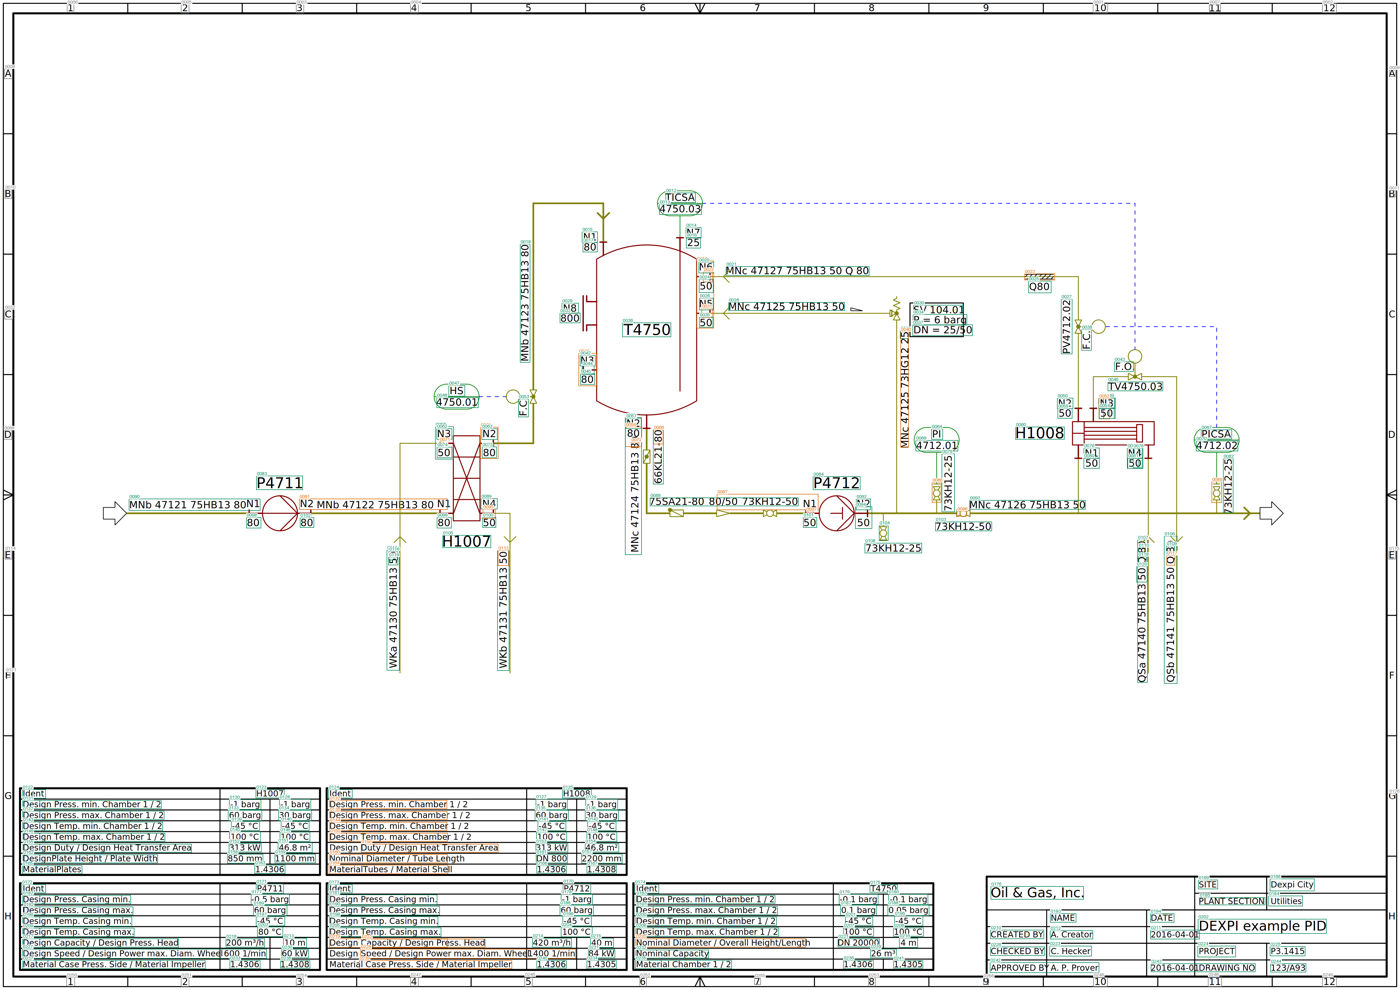

,id,text_raw,confidence
70,text-0071,+,0.107920
22,text-0023,TE,0.247335
112,text-0113,9,0.341718
95,text-0096,Y,0.342738
30,text-0031,一,0.349037
116,text-0117,Q,0.433897
85,text-0086,1004,0.484307
21,text-0022,+,0.494083
84,text-0085,1DO4,0.497607
94,text-0095,一,0.523293


In [7]:
annotated = pid_image.copy()
draw = ImageDraw.Draw(annotated)
font = ImageFont.load_default(size=16)
for d in detections:
    b = d["bounding_box"]
    color = "#777777" if not d["searchable"] else ("#dc6500" if d["needs_review"] else "#00865a")
    draw.rectangle((b["x_min"], b["y_min"], b["x_max"], b["y_max"]), outline=color, width=2)
    label = d["id"].removeprefix("text-")
    label_box = draw.textbbox((0, 0), label, font=font)
    label_width = label_box[2] - label_box[0] + 4
    label_height = label_box[3] - label_box[1] + 4
    lx = max(0, min(b["x_min"], IMAGE_WIDTH - label_width))
    ly = max(0, b["y_min"] - label_height)
    draw.rectangle((lx, ly, lx + label_width, ly + label_height), fill="white")
    draw.text((lx + 2, ly + 2 - label_box[1]), label, fill=color, font=font)
ANNOTATED_PATH = OUTPUT_DIR / "reference_pid_ocr_annotated.png"
annotated.save(ANNOTATED_PATH)
with Image.open(ANNOTATED_PATH) as saved:
    assert saved.size == pid_image.size
print(f"Regions: {len(detections)} | Review: {int(summary.needs_review.sum())} | "
      f"Mean confidence: {summary.confidence.mean():.3f}")
display(annotated.resize((1400, round(1400 * IMAGE_HEIGHT / IMAGE_WIDTH))))
display(summary.nsmallest(15, "confidence")[["id", "text_raw", "confidence"]])

## 6. Inspect an equipment tag or text fragment

This is a local text filter over OCR results, not retrieval or an LLM. The default `P4711` is a pump tag in this drawing. Change it to another visible label. An empty result does not establish that a tag is absent from the source; OCR may miss or misread it. Change `QUERY` to a label visible in the drawing. Crops retain nearby drawing context.

The query searches `searchable_summary`, which excludes drawing-border detections. The full OCR audit table and SVG comparison still retain them.

,document_id,page,image_width,image_height,id,text_raw,text_normalized,confidence,needs_review,source_rotation_ccw,...,x_max,y_max,center_x,center_y,x_min_normalized,y_min_normalized,x_max_normalized,y_max_normalized,center_x_normalized,center_y_normalized
82,dexpi_reference_pid,1,5000,3536,text-0083,P4711,P4711,0.998136,False,0,...,1081,1749,998.0,1724.0,0.1830,0.480486,0.2162,0.494627,0.1996,0.487557
170,dexpi_reference_pid,1,5000,3536,text-0171,P4711,P4711,0.999576,False,0,...,1013,3190,963.5,3173.0,0.1828,0.892534,0.2026,0.902149,0.1927,0.897342


text-0083 · P4711 · confidence 0.998


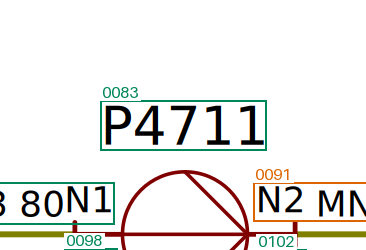

text-0171 · P4711 · confidence 1.000


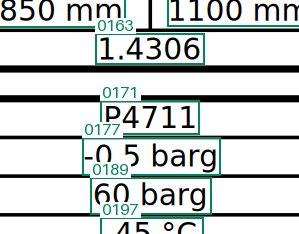

✓ outputs/reference_pid_ocr.json (371,922 bytes)
✓ outputs/reference_pid_ocr_annotated.png (1,003,460 bytes)
✓ outputs/reference_pid_ocr_summary.csv (59,554 bytes)


In [8]:
QUERY = "P4711"  # Pump tag present in this drawing.
matches = searchable_summary[searchable_summary.text_normalized.str.contains(normalize_text(QUERY), case=False, regex=False)]
display(matches)
if matches.empty:
    print(f"No OCR match for {QUERY!r}. Inspect the image or try another visible label.")
for _, row in matches.head(8).iterrows():
    padding = 100
    crop_box = (max(0, int(row.x_min) - padding), max(0, int(row.y_min) - padding),
                min(IMAGE_WIDTH, int(row.x_max) + padding),
                min(IMAGE_HEIGHT, int(row.y_max) + padding))
    print(f"{row['id']} · {row.text_raw} · confidence {row.confidence:.3f}")
    display(annotated.crop(crop_box))

for path in (JSON_PATH, ANNOTATED_PATH, CSV_PATH):
    assert path.is_file() and path.stat().st_size > 0
    print(f"✓ {path.relative_to(ROOT)} ({path.stat().st_size:,} bytes)")

## 7. Extract the SVG's embedded text independently

An SVG can store actual text strings in `<text>` elements. Read those strings directly from XML; this step requires neither rendering nor OCR. Each `<text>` element becomes one record, including text inside any nested `<tspan>` elements, with raw text, normalized text and source attributes.

Keep the XML element path and ancestor attributes for traceability. These are SVG layout instructions, **not pixel bounding boxes**. Computing rendered text bounds would require interpreting transforms, fonts and layout. The inventory also flags text in definitions or explicitly hidden containers, which is excluded from comparison. It does not expand `<use>` instances, evaluate CSS stylesheets or reconstruct complex text layout. The supplied SVG has no text in definitions or explicit hidden containers; for other SVGs, inspect these limitations before treating the inventory as visible text.

For PDF/PNG inputs, these sections skip SVG extraction and comparison. OCR results remain unchanged.

In [9]:
from collections import Counter, defaultdict, deque
from difflib import SequenceMatcher
from defusedxml import ElementTree as SafeET

SVG_NS = "http://www.w3.org/2000/svg"
SVG_TEXT_PATH = OUTPUT_DIR / "reference_pid_svg_text.json"
svg_records = []
svg_payload = None


def extract_svg_text(path):
    root = SafeET.parse(path).getroot()
    records = []
    non_rendered = {"defs", "symbol", "clipPath", "mask", "pattern", "marker", "metadata"}

    def visit(element, xml_path, ancestors, excluded=False):
        name = element.tag.rsplit("}", 1)[-1]
        style = dict(part.split(":", 1) for part in element.get("style", "").split(";") if ":" in part)
        style = {key.strip(): value.strip() for key, value in style.items()}
        hidden = (element.get("display") == "none" or style.get("display") == "none"
                  or element.get("visibility") in {"hidden", "collapse"}
                  or style.get("visibility") in {"hidden", "collapse"}
                  or element.get("opacity") == "0" or style.get("opacity") == "0")
        excluded = excluded or name in non_rendered or hidden
        if element.tag == f"{{{SVG_NS}}}text":
            raw = "".join(element.itertext())
            records.append({
                "id": f"svg-text-{len(records) + 1:04d}",
                "text_raw": raw, "text_normalized": normalize_text(raw),
                "xml_path": xml_path, "attributes": dict(element.attrib),
                "ancestor_attributes": ancestors,
                "comparison_eligible": bool(raw.strip()) and not excluded,
                "exclusion_reason": "definition/explicitly hidden container or empty text" if excluded or not raw.strip() else None,
            })
        sibling_counts = Counter()
        for child in element:
            child_name = child.tag.rsplit("}", 1)[-1]
            sibling_counts[child_name] += 1
            visit(child, f"{xml_path}/{child_name}[{sibling_counts[child_name]}]",
                  ancestors + [{"element": name, "attributes": dict(element.attrib)}], excluded)

    visit(root, "/svg[1]", [])
    return root, records

if INPUT_PATH.suffix.lower() == ".svg":
    svg_root, svg_records = extract_svg_text(INPUT_PATH)
    svg_payload = {
        "document_id": DOCUMENT_ID, "source_file": str(INPUT_PATH.relative_to(ROOT)),
        "source_sha256": payload["metadata"]["source_sha256"],
        "extraction_method": "XML text content; no OCR; one record per text element",
        "svg_attributes": dict(svg_root.attrib),
        "text_element_count": len(svg_records),
        "comparison_eligible_count": sum(r["comparison_eligible"] for r in svg_records),
        "text_elements": svg_records,
    }
    SVG_TEXT_PATH.write_text(json.dumps(svg_payload, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    assert len({r["id"] for r in svg_records}) == len(svg_records)
    assert len(svg_records) == len(list(svg_root.iter(f"{{{SVG_NS}}}text")))
    print(f"Extracted {len(svg_records)} SVG text elements; "
          f"{svg_payload['comparison_eligible_count']} eligible for comparison.")
    display(pd.DataFrame(svg_records)[["id", "text_raw", "text_normalized", "comparison_eligible"]].head(20))
    print(f"Saved {SVG_TEXT_PATH.relative_to(ROOT)}")
else:
    print("Skipped: embedded SVG text is available only for SVG input.")

Extracted 245 SVG text elements; 245 eligible for comparison.


,id,text_raw,text_normalized,comparison_eligible
0,svg-text-0001,1,1,True
1,svg-text-0002,1,1,True
2,svg-text-0003,2,2,True
3,svg-text-0004,2,2,True
4,svg-text-0005,3,3,True
5,svg-text-0006,3,3,True
6,svg-text-0007,4,4,True
7,svg-text-0008,4,4,True
8,svg-text-0009,5,5,True
9,svg-text-0010,5,5,True


Saved outputs/reference_pid_svg_text.json


## 8. Compare SVG text against OCR

First, pair **exact normalized strings one-to-one**, consuming each OCR occurrence once. If the SVG contains `80` ten times and OCR detects it eight times, at most eight occurrences match. Case and punctuation remain significant after the same normalization used for OCR.

This is a **text inventory comparison, not spatial matching**: matching duplicate strings does not establish that OCR found the same physical label. Matching IDs for repeated strings are bookkeeping references, not verified locations. The exact occurrence coverage below is not character accuracy or detection recall against a spatially labeled dataset.

For each unmatched SVG element, list up to three similar OCR strings as review suggestions (character similarity ≥ 0.50). Suggestions can reuse OCR regions, including exact matches elsewhere, and are never counted as matches. A source string may be missed, misread or merged/split across OCR regions. Likewise, OCR-only strings can be false positives or segmentation differences. No source text is injected into OCR exports.

In [10]:
COMPARISON_PATH = OUTPUT_DIR / "reference_pid_svg_ocr_comparison.csv"
COMPARISON_SUMMARY_PATH = OUTPUT_DIR / "reference_pid_svg_ocr_comparison_summary.json"
comparison = pd.DataFrame()


def compare_text_inventory(source_records, ocr_records):
    available = defaultdict(deque)
    for detection in ocr_records:
        available[detection["text_normalized"]].append(detection)
    rows, used = [], set()
    eligible = [record for record in source_records if record["comparison_eligible"]]
    for record in eligible:
        options = available[record["text_normalized"]]
        match = options.popleft() if options else None
        if match:
            used.add(match["id"])
        suggestions = []
        if match is None:
            ranked = sorted(
                ((SequenceMatcher(None, record["text_normalized"], d["text_normalized"],
                                  autojunk=False).ratio(), d) for d in ocr_records),
                key=lambda pair: (-pair[0], pair[1]["id"]))
            suggestions = [{"ocr_id": d["id"], "ocr_text": d["text_raw"],
                            "character_similarity": round(score, 4)}
                           for score, d in ranked[:3] if score >= 0.50]
        rows.append({
            "status": "exact_normalized_match" if match else "svg_without_exact_ocr_match",
            "svg_id": record["id"], "svg_text_raw": record["text_raw"],
            "svg_text_normalized": record["text_normalized"],
            "ocr_id": match["id"] if match else "",
            "ocr_text_raw": match["text_raw"] if match else "",
            "ocr_text_normalized": match["text_normalized"] if match else "",
            "ocr_confidence": match["confidence"] if match else None,
            "review_suggestions_json": json.dumps(suggestions, ensure_ascii=False),
        })
    for detection in ocr_records:
        if detection["id"] not in used:
            rows.append({
                "status": "ocr_without_exact_svg_match", "svg_id": "", "svg_text_raw": "",
                "svg_text_normalized": "", "ocr_id": detection["id"],
                "ocr_text_raw": detection["text_raw"],
                "ocr_text_normalized": detection["text_normalized"],
                "ocr_confidence": detection["confidence"], "review_suggestions_json": "[]",
            })
    return pd.DataFrame(rows, columns=["status", "svg_id", "svg_text_raw", "svg_text_normalized",
                                      "ocr_id", "ocr_text_raw", "ocr_text_normalized",
                                      "ocr_confidence", "review_suggestions_json"])

if svg_payload is not None:
    comparison = compare_text_inventory(svg_records, detections)
    counts = comparison.status.value_counts()
    matched = int(counts.get("exact_normalized_match", 0))
    source_count = svg_payload["comparison_eligible_count"]
    svg_unmatched = int(counts.get("svg_without_exact_ocr_match", 0))
    ocr_unmatched = int(counts.get("ocr_without_exact_svg_match", 0))
    assert matched + svg_unmatched == source_count
    assert matched + ocr_unmatched == len(detections)
    # Independent multiset check: repeated labels cannot inflate the exact-match count.
    source_counts = Counter(r["text_normalized"] for r in svg_records if r["comparison_eligible"])
    ocr_counts = Counter(d["text_normalized"] for d in detections)
    assert matched == sum((source_counts & ocr_counts).values())
    matched_rows = comparison[comparison.status == "exact_normalized_match"]
    assert matched_rows.ocr_id.is_unique and matched_rows.svg_id.is_unique
    report = {
        "document_id": DOCUMENT_ID, "source_sha256": svg_payload["source_sha256"],
        "method": "one-to-one normalized text multiset comparison; no spatial matching",
        "svg_text_elements_total": len(svg_records), "svg_text_elements_compared": source_count,
        "ocr_regions": len(detections), "exact_normalized_matches": matched,
        "svg_without_exact_ocr_match": svg_unmatched,
        "ocr_without_exact_svg_match": ocr_unmatched,
        "exact_svg_occurrence_coverage": matched / source_count if source_count else None,
        "ocr_exact_inventory_match_fraction": matched / len(detections) if detections else None,
        "limitations": ["No spatial verification of repeated labels.",
                        "One SVG text element may correspond to multiple OCR regions, or vice versa.",
                        "Fuzzy suggestions are unverified and excluded from match counts.",
                        "Coverage is not character accuracy or spatial detection recall."],
    }
    comparison.to_csv(COMPARISON_PATH, index=False, encoding="utf-8")
    COMPARISON_SUMMARY_PATH.write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    assert len(pd.read_csv(COMPARISON_PATH, keep_default_na=False)) == len(comparison)
    print(f"SVG elements compared: {source_count} | OCR regions: {len(detections)}")
    print(f"Exact normalized matches: {matched} | SVG unmatched: {svg_unmatched} | OCR unmatched: {ocr_unmatched}")
    if source_count:
        print(f"Exact SVG text occurrence coverage: {matched / source_count:.1%} (not spatial recall)")
    display(comparison[comparison.status == "svg_without_exact_ocr_match"].head(20))
    display(comparison[comparison.status == "ocr_without_exact_svg_match"].head(20))
    print(f"Saved {COMPARISON_PATH.name} and {COMPARISON_SUMMARY_PATH.name}")
else:
    print("Skipped: no SVG text inventory for this input.")

SVG elements compared: 245 | OCR regions: 256
Exact normalized matches: 187 | SVG unmatched: 58 | OCR unmatched: 69
Exact SVG text occurrence coverage: 76.3% (not spatial recall)


,status,svg_id,svg_text_raw,svg_text_normalized,ocr_id,ocr_text_raw,ocr_text_normalized,ocr_confidence,review_suggestions_json
11,svg_without_exact_ocr_match,svg-text-0012,6,6,,,,NaN,"[{""ocr_id"": ""text-0252"", ""ocr_text"": ""6"", ""cha..."
13,svg_without_exact_ocr_match,svg-text-0014,7,7,,,,NaN,"[{""ocr_id"": ""text-0255"", ""ocr_text"": ""7"", ""cha..."
24,svg_without_exact_ocr_match,svg-text-0025,H,H,,,,NaN,"[{""ocr_id"": ""text-0047"", ""ocr_text"": ""HS"", ""ch..."
25,svg_without_exact_ocr_match,svg-text-0026,H,H,,,,NaN,"[{""ocr_id"": ""text-0047"", ""ocr_text"": ""HS"", ""ch..."
27,svg_without_exact_ocr_match,svg-text-0028,G,G,,,,NaN,"[{""ocr_id"": ""text-0126"", ""ocr_text"": ""G"", ""cha..."
29,svg_without_exact_ocr_match,svg-text-0030,F,F,,,,NaN,"[{""ocr_id"": ""text-0121"", ""ocr_text"": ""F"", ""cha..."
33,svg_without_exact_ocr_match,svg-text-0034,D,D,,,,NaN,"[{""ocr_id"": ""text-0068"", ""ocr_text"": ""D"", ""cha..."
35,svg_without_exact_ocr_match,svg-text-0036,C,C,,,,NaN,"[{""ocr_id"": ""text-0032"", ""ocr_text"": ""C"", ""cha..."
40,svg_without_exact_ocr_match,svg-text-0041,APPROVED BY,APPROVED BY,,,,NaN,"[{""ocr_id"": ""text-0242"", ""ocr_text"": ""APPROVED..."
41,svg_without_exact_ocr_match,svg-text-0042,A. P. Prover,A. P. Prover,,,,NaN,"[{""ocr_id"": ""text-0242"", ""ocr_text"": ""APPROVED..."


,status,svg_id,svg_text_raw,svg_text_normalized,ocr_id,ocr_text_raw,ocr_text_normalized,ocr_confidence,review_suggestions_json
245,ocr_without_exact_svg_match,,,,text-0019,%t 215,%t 215,0.619818,[]
246,ocr_without_exact_svg_match,,,,text-0022,+,+,0.494083,[]
247,ocr_without_exact_svg_match,,,,text-0023,TE,TE,0.247335,[]
248,ocr_without_exact_svg_match,,,,text-0031,一,一,0.349037,[]
249,ocr_without_exact_svg_match,,,,text-0034,P = 6 barΦ,P = 6 barΦ,0.947497,[]
250,ocr_without_exact_svg_match,,,,text-0037,DN = 25/$0,DN = 25/$0,0.908897,[]
251,ocr_without_exact_svg_match,,,,text-0041,218,218,0.721488,[]
252,ocr_without_exact_svg_match,,,,text-0043,F.O,F.O,0.938938,[]
253,ocr_without_exact_svg_match,,,,text-0044,T,T,0.984719,[]
254,ocr_without_exact_svg_match,,,,text-0049,3:0,3:0,0.800443,[]


Saved reference_pid_svg_ocr_comparison.csv and reference_pid_svg_ocr_comparison_summary.json


### Inspect a disagreement

Pick an unmatched SVG string, examine its suggested OCR readings, and locate those OCR IDs in the annotation or CSV. Check the source drawing before deciding whether this is a recognition error, a segmentation difference or a missed label. The complete comparison CSV includes all exact matches and disagreements; the tables above only preview them.

## 9. Identify and classify tag candidates with regex

This first rule-based pass searches **OCR detections**, not the embedded SVG text. It preserves the original detection ID, OCR confidence and box so every candidate can be checked on the drawing. OCR exports remain unchanged.

**Two steps:** (1) regex finds a tag-shaped substring; (2) a prefix lookup assigns a provisional category and type. The editable rules below are assumptions for this demonstration, not a verified engineering standard. Every result requires confirmation against the drawing legend or tag register.

The initial pattern accepts 1–5 letters, an optional hyphen or space, a 3–6 digit identifier, an optional one-letter suffix and an optional one- or two-digit dotted suffix. Examples: `P4711`, `P-101`, `P-101A`, `PV4712.02`, `SV 104.01`. Boundaries prevent extracting a shorter valid-looking tag from a longer code. These digit limits intentionally exclude short nozzle labels such as `N1` and project identifiers such as `P3.1415`; adapt them for another project's conventions.

Known pipe-service prefixes and non-target labels are excluded. Unknown prefixes remain `unknown` candidates. Standalone instrument function labels such as `PI`, `PICSA`, `HS` and `TICSA` are recorded separately as **incomplete instrument labels**: the loop number may be in another OCR region. This stage does not join neighboring text or invent missing numbers.

In [11]:
# Editable demonstration rules; validate these against the project's legend/register.
PREFIX_RULES = {
    "P": ("equipment", "pump"),
    "H": ("equipment", "heat_exchanger"),
    "T": ("equipment", "tank_or_vessel"),
    "PV": ("instrument", "pressure_valve"),
    "TV": ("instrument", "temperature_valve"),
    "SV": ("instrument", "safety_valve"),
    "PI": ("instrument", "pressure_indicator"),
    "PT": ("instrument", "pressure_transmitter"),
    "PIC": ("instrument", "pressure_indicating_controller"),
    "PICSA": ("instrument", "pressure_function_label"),
    "TI": ("instrument", "temperature_indicator"),
    "TT": ("instrument", "temperature_transmitter"),
    "TIC": ("instrument", "temperature_indicating_controller"),
    "TICSA": ("instrument", "temperature_function_label"),
    "FI": ("instrument", "flow_indicator"),
    "FT": ("instrument", "flow_transmitter"),
    "FIC": ("instrument", "flow_indicating_controller"),
    "LI": ("instrument", "level_indicator"),
    "LT": ("instrument", "level_transmitter"),
    "LIC": ("instrument", "level_indicating_controller"),
    "HS": ("instrument", "hand_switch"),
}
# The supplied SVG includes these non-equipment pipe-service/size/nozzle labels.
EXCLUDED_PREFIXES = {"N", "DN", "PN", "Q", "MNB", "MNC", "WKA", "WKB", "QSA", "QSB"}
FUNCTION_PREFIXES = {prefix for prefix, (category, _) in PREFIX_RULES.items()
                     if category == "instrument" and prefix not in {"PV", "TV", "SV"}}
TAG_PATTERN = re.compile(
    r"(?<![\w./-])"
    r"(?P<prefix>[A-Z]{1,5})(?:\s*-\s*|\s*)"
    r"(?P<number>\d{3,6})(?P<letter_suffix>[A-Z]?)"
    r"(?P<dot_suffix>\.\d{1,2})?"
    r"(?![\w./-])",
    re.IGNORECASE,
)
FUNCTION_PATTERN = re.compile(
    r"(?:" + "|".join(sorted(FUNCTION_PREFIXES, key=lambda s: (-len(s), s))) + r")",
    re.IGNORECASE,
)


def identify_tag_candidates(text):
    normalized = normalize_text(text)
    found = []
    for match in TAG_PATTERN.finditer(normalized):
        prefix = match.group("prefix").upper()
        if prefix in EXCLUDED_PREFIXES:
            continue
        category, type_name = PREFIX_RULES.get(prefix, ("unknown", "unknown"))
        identifier = (match.group("number") + match.group("letter_suffix").upper()
                      + (match.group("dot_suffix") or ""))
        found.append({
            "matched_text": match.group(0),
            "candidate_kind": "complete_tag_candidate",
            "tag_normalized": prefix + identifier,
            "prefix": prefix, "identifier": identifier,
            "category": category, "type": type_name,
            "rule_id": f"prefix:{prefix}" if prefix in PREFIX_RULES else "unknown_prefix",
            "match_span_normalized_text": list(match.span()),
        })
    if not found and FUNCTION_PATTERN.fullmatch(normalized):
        prefix = normalized.upper()
        category, type_name = PREFIX_RULES[prefix]
        found.append({
            "matched_text": normalized, "candidate_kind": "instrument_function_only",
            "tag_normalized": None, "prefix": prefix, "identifier": None,
            "category": category, "type": type_name,
            "rule_id": f"standalone_function:{prefix}",
            "match_span_normalized_text": [0, len(normalized)],
        })
    return found

# Check the rule boundaries, categories, normalization and incomplete labels.
assert identify_tag_candidates("P-101")[0]["tag_normalized"] == "P101"
assert identify_tag_candidates("p – 101a")[0]["tag_normalized"] == "P101A"
assert identify_tag_candidates("PV4712.02")[0]["category"] == "instrument"
assert identify_tag_candidates("SV 104.01")[0]["tag_normalized"] == "SV104.01"
assert identify_tag_candidates("H1007")[0]["category"] == "equipment"
assert identify_tag_candidates("ZZ-123")[0]["category"] == "unknown"
assert identify_tag_candidates("PI")[0]["tag_normalized"] is None
assert len(identify_tag_candidates("P4711 / P4712")) == 2
for non_tag in ("N1", "DN 800", "Q80", "P3.1415", "75HB13", "73KH12-50",
                "MNb 47121 75HB13 80", "P = 6 barg", "P1234567", "P4711.123",
                "123/A93", "Design Press. Casing min."):
    assert not identify_tag_candidates(non_tag), non_tag
print("Regex examples and exclusion checks passed.")

Regex examples and exclusion checks passed.


### Classify occurrences and export

Each row is one candidate occurrence, not one unique physical asset. The same tag may appear on the drawing and in a specification table. `tag_normalized` removes separators between the prefix and number to group variants such as `P-101` and `P101`; raw text is retained. Standalone instrument function labels have no complete tag value.

Boxes belong to the **parent OCR region**. If one region contains multiple tags, they share that region's box; regex cannot determine each substring's pixel bounds. OCR confidence describes recognition, not classification certainty. All classifications have `classification_status = provisional` and `needs_review = True`.

In [12]:
tag_candidates = []
for detection in searchable_detections:
    for candidate in identify_tag_candidates(detection["text_raw"]):
        tag_candidates.append({
            "id": f"tag-{len(tag_candidates) + 1:04d}",
            "document_id": DOCUMENT_ID, "page": PAGE,
            **candidate,
            "source": "ocr", "source_detection_id": detection["id"],
            "region_type": detection["region_type"],
            "source_text_raw": detection["text_raw"],
            "source_text_normalized": detection["text_normalized"],
            "ocr_confidence": detection["confidence"],
            "bounding_box": detection["bounding_box"],
            "bounding_box_normalized": detection["bounding_box_normalized"],
            "geometry_scope": "parent_ocr_region",
            "classification_status": "provisional", "needs_review": True,
        })

TAG_JSON_PATH = OUTPUT_DIR / "reference_pid_tags.json"
TAG_CSV_PATH = OUTPUT_DIR / "reference_pid_tags.csv"
tag_payload = {
    "document_id": DOCUMENT_ID, "page": PAGE,
    "image_width": IMAGE_WIDTH, "image_height": IMAGE_HEIGHT,
    "source_sha256": payload["metadata"]["source_sha256"],
    "method": "regex candidates from OCR, followed by editable prefix lookup",
    "rules": {
        "tag_pattern": TAG_PATTERN.pattern,
        "pattern_flags": ["IGNORECASE"],
        "prefix_rules": {k: {"category": v[0], "type": v[1]} for k, v in PREFIX_RULES.items()},
        "excluded_prefixes": sorted(EXCLUDED_PREFIXES),
        "standalone_function_prefixes": sorted(FUNCTION_PREFIXES),
        "canonicalization": "uppercase prefix and suffix; remove prefix/number separator; preserve dotted suffix",
        "verified_against_legend_or_register": False,
    },
    "candidates": tag_candidates,
}
TAG_JSON_PATH.write_text(json.dumps(tag_payload, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
tag_columns = ["id", "document_id", "page", "candidate_kind", "matched_text", "tag_normalized",
               "prefix", "identifier", "category", "type", "rule_id", "region_type", "source_detection_id",
               "source_text_raw", "ocr_confidence", "classification_status", "needs_review", "geometry_scope"]
tag_rows = [{**{key: c[key] for key in tag_columns}, **c["bounding_box"]} for c in tag_candidates]
tag_table = pd.DataFrame(tag_rows, columns=tag_columns + ["x_min", "y_min", "x_max", "y_max"])
tag_table.to_csv(TAG_CSV_PATH, index=False, encoding="utf-8")
assert len(pd.read_csv(TAG_CSV_PATH, keep_default_na=False)) == len(tag_candidates)
assert json.loads(TAG_JSON_PATH.read_text(encoding="utf-8")) == tag_payload
assert len({c["id"] for c in tag_candidates}) == len(tag_candidates)
assert all(c["source_detection_id"] in {d["id"] for d in detections} for c in tag_candidates)
complete = tag_table[tag_table.candidate_kind == "complete_tag_candidate"]
print(f"{len(complete)} complete tag occurrences; {complete.tag_normalized.nunique()} unique candidate tags")
print(f"{int((tag_table.candidate_kind == 'instrument_function_only').sum())} incomplete instrument function labels")
display(tag_table[["id", "matched_text", "tag_normalized", "category", "type",
                   "candidate_kind", "source_detection_id", "ocr_confidence"]])
print(f"Saved {TAG_JSON_PATH.name} and {TAG_CSV_PATH.name}")

16 complete tag occurrences; 11 unique candidate tags
4 incomplete instrument function labels


,id,matched_text,tag_normalized,category,type,candidate_kind,source_detection_id,ocr_confidence
0,tag-0001,TICSA,None,instrument,temperature_function_label,instrument_function_only,text-0012,0.998804
1,tag-0002,t 215,T215,equipment,tank_or_vessel,complete_tag_candidate,text-0019,0.619818
2,tag-0003,PV4712.02,PV4712.02,instrument,pressure_valve,complete_tag_candidate,text-0027,0.999826
3,tag-0004,SV 104.01,SV104.01,instrument,safety_valve,complete_tag_candidate,text-0030,0.996066
4,tag-0005,T4750,T4750,equipment,tank_or_vessel,complete_tag_candidate,text-0036,0.999789
5,tag-0006,TV4750.03,TV4750.03,instrument,temperature_valve,complete_tag_candidate,text-0046,0.999843
6,tag-0007,HS,None,instrument,hand_switch,instrument_function_only,text-0047,0.999545
7,tag-0008,H1008,H1008,equipment,heat_exchanger,complete_tag_candidate,text-0060,0.997458
8,tag-0009,PI,None,instrument,pressure_indicator,instrument_function_only,text-0064,0.967020
9,tag-0010,PICSA,None,instrument,pressure_function_label,instrument_function_only,text-0067,0.999324


Saved reference_pid_tags.json and reference_pid_tags.csv


### Inspect classified tags

Filter by the rule-assigned category below. Repeated tags remain separate so you can inspect every detected location. This view is additional to the literal OCR-text search in section 6; that earlier search still includes all OCR text.

,id,matched_text,type,source_detection_id
1,tag-0002,t 215,tank_or_vessel,text-0019
4,tag-0005,T4750,tank_or_vessel,text-0036
7,tag-0008,H1008,heat_exchanger,text-0060
10,tag-0011,P4711,pump,text-0083
11,tag-0012,P4712,pump,text-0084
12,tag-0013,H1007,heat_exchanger,text-0105
13,tag-0014,H1007,heat_exchanger,text-0123
14,tag-0015,H1008,heat_exchanger,text-0125
15,tag-0016,P4712,pump,text-0170
16,tag-0017,P4711,pump,text-0171


t 215: tank_or_vessel (provisional) · text-0019


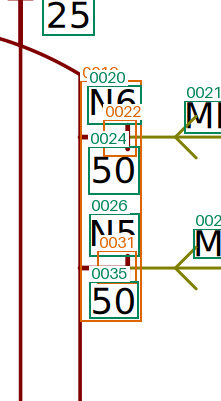

T4750: tank_or_vessel (provisional) · text-0036


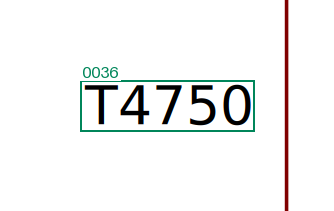

H1008: heat_exchanger (provisional) · text-0060


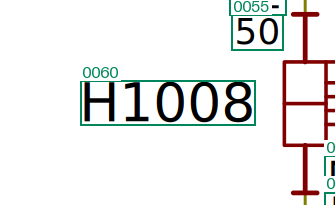

P4711: pump (provisional) · text-0083


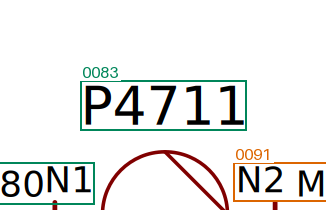

P4712: pump (provisional) · text-0084


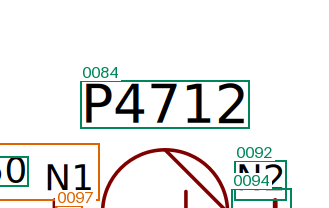

H1007: heat_exchanger (provisional) · text-0105


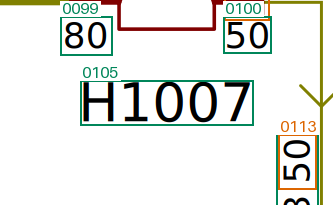

H1007: heat_exchanger (provisional) · text-0123


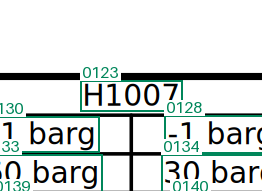

H1008: heat_exchanger (provisional) · text-0125


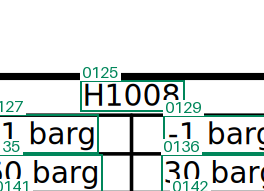

In [13]:
CATEGORY = "equipment"  # "equipment", "instrument", "unknown", or "all"
if CATEGORY not in {"equipment", "instrument", "unknown", "all"}:
    raise ValueError("Choose equipment, instrument, unknown, or all.")
classified_matches = tag_table if CATEGORY == "all" else tag_table[tag_table.category == CATEGORY]
display(classified_matches[["id", "matched_text", "type", "source_detection_id"]])
for _, row in classified_matches.head(8).iterrows():
    pad = 80
    crop_box = (max(0, int(row.x_min) - pad), max(0, int(row.y_min) - pad),
                min(IMAGE_WIDTH, int(row.x_max) + pad), min(IMAGE_HEIGHT, int(row.y_max) + pad))
    print(f"{row.matched_text}: {row['type']} (provisional) · {row.source_detection_id}")
    display(annotated.crop(crop_box))

## 10. Tag search → relevant region → crops and nearby text

**How is the relevant region selected?** First locate the query in searchable OCR text and grouped instrument candidates. Each hit supplies a bounding box and `region_type`. A region type is a category, not a unique table: we configure individual table rectangles (`region_id`) below. A table hit selects that specific table; a title-block hit selects the title block. A process-drawing hit starts with a padded local window around its OCR box. Select same-region OCR boxes that intersect this initial window, even if their centers lie outside it; then expand the crop once to contain those full boxes, with an 8-pixel margin. The initial window determines relevance, while the expanded crop preserves selected text. Unconfigured table hits fall back to a clearly labeled local window.

All matching locations are returned, grouped by `region_type`; none is silently chosen as the only answer. Thus `P4711` should return a process occurrence and an equipment-table occurrence. Nearby OCR comes from the original context selection and the same region type. Table selection still uses centers within the individual configured table; all selected text boxes are included in full. Crop expansion does not recursively pull in more text. Undetected text and incidental labels entering the expanded crop can still be incomplete. It is supporting spatial context, **not proof that every nearby label belongs to that asset**.

The default `SEARCH_MODE = "contains"` accepts incomplete tags: `PI4712` finds `PI4712.01`, including spatially grouped tags. Partial matches are labeled and complete matches lead each region group. Use `SEARCH_MODE = "exact"` to require a whole tag. In exact mode: `P4711` does not match `P47110` or `P4711A`. Case and prefix-number separators are normalized (`P-4711` and `P4711` are treated as equivalent). No fuzzy correction is applied. All occurrences of a repeated tag inside one OCR box are counted, but share that box because substring pixel coordinates are unavailable.

The helper functions live in `pid_search.py` for reuse in a future Streamlit interface. This section loads saved OCR/image outputs, so you can run its two cells independently after restarting the kernel. Change the query and rerun just the second cell. Red outlines mark matching OCR regions; blue outlines mark nearby OCR. Long text strings are preserved.

Search also includes spatially grouped instrument tags. Both complete and split occurrences are returned, even when a complete match already exists. Grouped crops highlight each contributing OCR box. Competing groupings are returned with `ambiguous=True` for review.

In [1]:
from pathlib import Path
import json
import re
import sys
import pandas as pd
from PIL import Image
from IPython.display import display

SEARCH_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "pid_search.py").is_file())
if str(SEARCH_ROOT) not in sys.path:
    sys.path.insert(0, str(SEARCH_ROOT))
import importlib
import pid_search
importlib.reload(pid_search)  # Pick up helper edits in an already-open kernel.
from pid_search import retrieve_tag, save_search_results

search_ocr = json.loads((SEARCH_ROOT / "outputs/reference_pid_searchable.json").read_text(encoding="utf-8"))
with Image.open(SEARCH_ROOT / "outputs/reference_pid.png") as source_image:
    search_image = source_image.convert("RGB")

# Separate table instances, based on the reference drawing's visible layout.
# They do not encode equipment tags: the location of a matching OCR box selects a table.
# Adjust these normalized bounds for another drawing.
REGION_INSTANCES = [
    {"region_id": "table_upper_left", "region_type": "equipment_data_table",
     "bounds_normalized": {"x_min": 0.014, "y_min": 0.795, "x_max": 0.229, "y_max": 0.885}},
    {"region_id": "table_upper_middle", "region_type": "equipment_data_table",
     "bounds_normalized": {"x_min": 0.233, "y_min": 0.795, "x_max": 0.449, "y_max": 0.885}},
    {"region_id": "table_lower_left", "region_type": "equipment_data_table",
     "bounds_normalized": {"x_min": 0.014, "y_min": 0.89, "x_max": 0.229, "y_max": 0.982}},
    {"region_id": "table_lower_middle", "region_type": "equipment_data_table",
     "bounds_normalized": {"x_min": 0.233, "y_min": 0.89, "x_max": 0.449, "y_max": 0.982}},
    {"region_id": "table_lower_right", "region_type": "equipment_data_table",
     "bounds_normalized": {"x_min": 0.452, "y_min": 0.89, "x_max": 0.668, "y_max": 0.982}},
    {"region_id": "title_block_main", "region_type": "title_block",
     "bounds_normalized": {"x_min": 0.70, "y_min": 0.88, "x_max": 0.99, "y_max": 0.985}},
]
print("Loaded searchable OCR and the clean page image. Tag search is ready.")

Loaded searchable OCR and the clean page image. Tag search is ready.


1 matching OCR occurrences; 1 text matches

process_drawing: 1 occurrence(s)
text-0064 → local-instrument-occurrence-0006 (local_spatial_window)
OCR text: PI4712.01 | partial match | confidence: 0.967


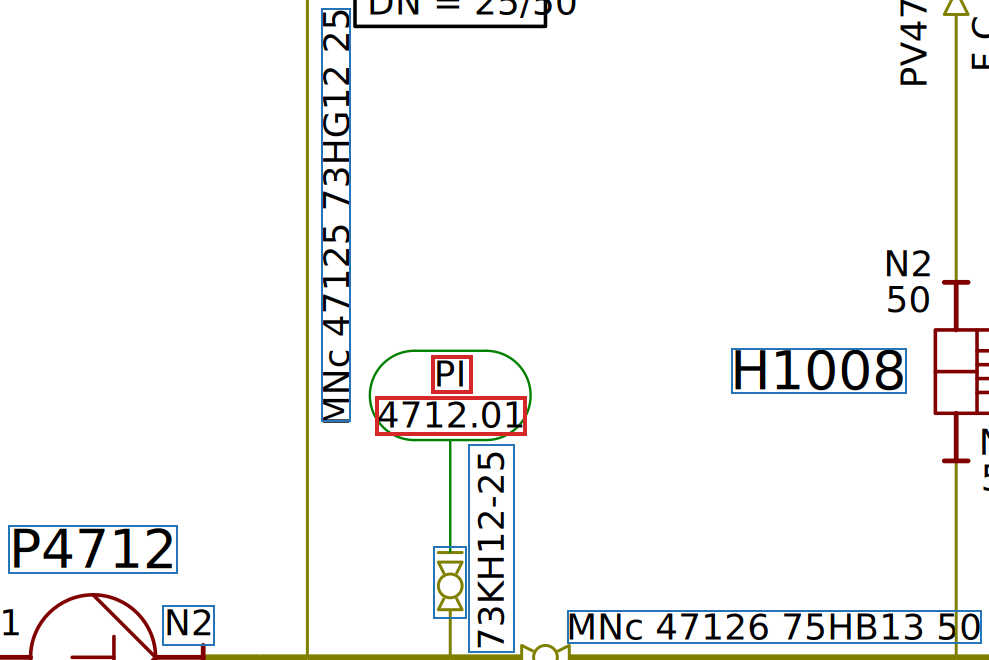

,id,text_raw,confidence,region_type,bounding_box
0,text-0040,MNc 47125 73HG12 25,0.957417,process_drawing,"{'x_min': 3216, 'y_min': 1184, 'x_max': 3245, ..."
1,text-0060,H1008,0.997458,process_drawing,"{'x_min': 3626, 'y_min': 1524, 'x_max': 3801, ..."
2,text-0079,73KH12-25,0.998997,process_drawing,"{'x_min': 3363, 'y_min': 1620, 'x_max': 3409, ..."
3,text-0084,P4712,0.999649,process_drawing,"{'x_min': 2903, 'y_min': 1701, 'x_max': 3072, ..."
4,text-0086,1004,0.484307,process_drawing,"{'x_min': 3328, 'y_min': 1722, 'x_max': 3361, ..."
5,text-0092,N2,0.998692,process_drawing,"{'x_min': 3057, 'y_min': 1781, 'x_max': 3109, ..."
6,text-0093,MNc 47126 75HB13 50,0.977258,process_drawing,"{'x_min': 3462, 'y_min': 1786, 'x_max': 3876, ..."


Saved grouped results and highlighted crops to outputs/search/PI4712/search_results.json


In [2]:
TAG_QUERY = "PI4712"
SEARCH_MODE = "contains"  # "contains" (partial tags) or "exact" (whole tags)
search_result = retrieve_tag(search_ocr, TAG_QUERY, REGION_INSTANCES, match_mode=SEARCH_MODE)
query_folder = re.sub(r"[^A-Za-z0-9_-]", "_", search_result["query_normalized"])
search_output = SEARCH_ROOT / "outputs" / "search" / query_folder
search_report_path = save_search_results(search_result, search_image, search_output)
print(f"{search_result['occurrence_count']} matching OCR occurrences; "
      f"{search_result['tag_match_count']} text matches")
if not search_result["groups"]:
    print("No match in the selected search mode. Check the spelling or inspect the drawing for an OCR error.")
for region_type, occurrences in search_result["groups"].items():
    print(f"\n{region_type}: {len(occurrences)} occurrence(s)")
    for occurrence in occurrences:
        print(f"{occurrence['source_detection_id']} → {occurrence['region_id']} "
              f"({occurrence['region_selection_method']})")
        print(f"OCR text: {occurrence['matched_text']} | {occurrence['match_quality']} match | confidence: {occurrence['ocr_confidence']:.3f}")
        with Image.open(search_output / occurrence["crop_file"]) as crop:
            display(crop.copy())
        display(pd.DataFrame(occurrence["nearby_ocr"],
                             columns=["id", "text_raw", "confidence", "region_type", "bounding_box"]))
print(f"Saved grouped results and highlighted crops to {search_report_path.relative_to(SEARCH_ROOT)}")

## 11. Group split instrument labels and build an inventory

A tag such as `PT133035` can appear as `PT` above `133035` in separate OCR boxes. Build candidate instrument occurrences **before search**, using the editable prefix list in `pid_instruments.py`. Also retain complete instrument tags and consolidate repeated canonical tags into one inventory row with multiple occurrences.

Group only standalone recognized prefixes and identifiers in `process_drawing`. The identifier must lie just below and horizontally aligned, or immediately to the right on the same line. Distances scale with local text height. Suffixes and dotted identifiers are retained (`HZ` + `133065C`, `PI` + `4712.01`). Other regions are not spatially grouped, though complete tags there can be inventoried.

Each occurrence retains source IDs, source texts, individual boxes, a combined box, geometry evidence and the minimum source OCR confidence. That confidence is **not** a grouping probability. All classifications remain provisional. Multiple qualifying partners or shared fragments are explicitly marked ambiguous; alternatives are not silently discarded. Prefixes without partners are listed separately.

This does not detect instrument circles or infer engineering connectivity. Unknown prefixes, OCR spelling errors, reversed layouts or widely separated fragments can be missed. Raw OCR remains unchanged. Search includes these candidates alongside direct OCR matches, with both source boxes highlighted.

In [16]:
from pathlib import Path
import json
import sys
import pandas as pd

INVENTORY_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pid_instruments.py").exists())
if str(INVENTORY_ROOT) not in sys.path:
    sys.path.insert(0, str(INVENTORY_ROOT))
from pid_instruments import build_instrument_inventory
inventory_source = json.loads((INVENTORY_ROOT / "outputs/reference_pid_searchable.json").read_text(encoding="utf-8"))
instrument_inventory = build_instrument_inventory(inventory_source)
instrument_list = pd.DataFrame(instrument_inventory["instruments"], columns=[
    "canonical_tag", "prefix", "category", "occurrence_count", "occurrence_ids", "region_types",
    "has_grouped_occurrences", "ambiguous", "needs_review"])
INVENTORY_JSON = INVENTORY_ROOT / "outputs/reference_pid_instrument_inventory.json"
INVENTORY_CSV = INVENTORY_ROOT / "outputs/reference_pid_instrument_list.csv"
INVENTORY_JSON.write_text(json.dumps(instrument_inventory, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
instrument_list.to_csv(INVENTORY_CSV, index=False)
assert sum(row["occurrence_count"] for row in instrument_inventory["instruments"]) == len(instrument_inventory["occurrences"])
assert all(o["source_detection_ids"] for o in instrument_inventory["occurrences"])
print(f"{len(instrument_list)} candidate instruments; {len(instrument_inventory['occurrences'])} occurrences")
display(instrument_list)
display(pd.DataFrame(instrument_inventory["occurrences"]))
print(f"Saved {INVENTORY_JSON.name} and {INVENTORY_CSV.name}")

7 candidate instruments; 7 occurrences


,canonical_tag,prefix,category,occurrence_count,occurrence_ids,region_types,has_grouped_occurrences,ambiguous,needs_review
0,HS4750.01,HS,instrument,1,[instrument-occurrence-0005],[process_drawing],True,False,True
1,PI4712.01,PI,instrument,1,[instrument-occurrence-0006],[process_drawing],True,False,True
2,PICSA4712.02,PICSA,instrument,1,[instrument-occurrence-0007],[process_drawing],True,False,True
3,PV4712.02,PV,instrument,1,[instrument-occurrence-0001],[process_drawing],False,False,True
4,SV104.01,SV,instrument,1,[instrument-occurrence-0002],[process_drawing],False,False,True
5,TICSA4750.03,TICSA,instrument,1,[instrument-occurrence-0004],[process_drawing],True,False,True
6,TV4750.03,TV,instrument,1,[instrument-occurrence-0003],[process_drawing],False,False,True


,id,canonical_tag,prefix,identifier,category,region_type,document_id,page,source_detection_ids,source_texts,...,bounding_box,ocr_confidence,source_confidences,match_method,geometry_evidence,match_span_normalized_text,classification_status,ambiguous,needs_review,competing_pair_count
0,instrument-occurrence-0001,PV4712.02,PV,4712.02,instrument,process_drawing,dexpi_reference_pid,1,[text-0027],[PV4712.02],...,"{'x_min': 3789, 'y_min': 1067, 'x_max': 3829, ...",0.999826,[0.999826278951433],complete_ocr_tag,None,"[0, 9]",provisional,False,True,NaN
1,instrument-occurrence-0002,SV104.01,SV,104.01,instrument,process_drawing,dexpi_reference_pid,1,[text-0030],[SV 104.01],...,"{'x_min': 3262, 'y_min': 1089, 'x_max': 3439, ...",0.996066,[0.996066325240665],complete_ocr_tag,None,"[0, 9]",provisional,False,True,NaN
2,instrument-occurrence-0003,TV4750.03,TV,4750.03,instrument,process_drawing,dexpi_reference_pid,1,[text-0046],[TV4750.03],...,"{'x_min': 3956, 'y_min': 1363, 'x_max': 4153, ...",0.999843,[0.9998427960607741],complete_ocr_tag,None,"[0, 9]",provisional,False,True,NaN
3,instrument-occurrence-0004,TICSA4750.03,TICSA,4750.03,instrument,process_drawing,dexpi_reference_pid,1,"[text-0012, text-0013]","[TICSA, 4750.03]",...,"{'x_min': 2354, 'y_min': 688, 'x_max': 2505, '...",0.998804,"[0.9988036274909973, 0.9997284412384033]",spatially_grouped,"{'arrangement': 'number_below_prefix', 'gap_in...",None,provisional,False,True,0.0
4,instrument-occurrence-0005,HS4750.01,HS,4750.01,instrument,process_drawing,dexpi_reference_pid,1,"[text-0047, text-0048]","[HS, 4750.01]",...,"{'x_min': 1559, 'y_min': 1376, 'x_max': 1708, ...",0.995865,"[0.9995449185371399, 0.995864919253758]",spatially_grouped,"{'arrangement': 'number_below_prefix', 'gap_in...",None,provisional,False,True,0.0
5,instrument-occurrence-0006,PI4712.01,PI,4712.01,instrument,process_drawing,dexpi_reference_pid,1,"[text-0064, text-0069]","[PI, 4712.01]",...,"{'x_min': 3270, 'y_min': 1531, 'x_max': 3421, ...",0.967020,"[0.9670195877552032, 0.9978958283151899]",spatially_grouped,"{'arrangement': 'number_below_prefix', 'gap_in...",None,provisional,False,True,0.0
6,instrument-occurrence-0007,PICSA4712.02,PICSA,4712.02,instrument,process_drawing,dexpi_reference_pid,1,"[text-0067, text-0070]","[PICSA, 4712.02]",...,"{'x_min': 4271, 'y_min': 1534, 'x_max': 4421, ...",0.999324,"[0.9993237495422364, 0.9996246950966972]",spatially_grouped,"{'arrangement': 'number_below_prefix', 'gap_in...",None,provisional,False,True,0.0


Saved reference_pid_instrument_inventory.json and reference_pid_instrument_list.csv


## Review notes and next milestone

- JSON describes **detected text regions**, not engineering symbols or pipe connectivity. Section 9 adds provisional tag candidates, not verified equipment identities.
- Read the lowest-confidence crops and a sample of high-confidence ones. Check for missed labels and overlap-deduplication mistakes. IDs are deterministic for a fixed OCR run but may change if settings or dependencies change.
- SVG font substitution can change rendering if the source font is not installed. The source SVG uses Calibri; compare the clean PNG against the original drawing in your viewer.
- Source provenance is retained via a SHA-256 hash. Keep the original drawing and `uv.lock` with the outputs.
- A later Streamlit milestone can use the coordinates to highlight selected tags, then connect manuals, procedures, the tag register and maintenance history.

References: [CairoSVG rendering options](https://cairosvg.org/documentation/) · [RapidOCR project](https://github.com/RapidAI/RapidOCR) · [RapidOCR 1.x examples](https://huggingface.co/spaces/RapidAI/RapidOCR/blob/main/app.py).